# Who Gets the Mortgage? — first submission code
**Course:** Big Data, Machine Learning, with Applications to Economics and Finance (ICEF, HSE)
**Author:** Vladimir Aristov · September 2026

Reproduces all numbers, tables and figures from the first-submission report:
1. download HMDA home-purchase applications for 2024 and 2025 (FFIEC Data Browser API);
2. build the analysis sample;
3. descriptive statistics and figures.

The same code is in `01_build_sample.py` and `02_eda.py`. The raw files are ~3.3 GB in total, the whole notebook runs in about 6 minutes.

In [1]:
import shutil, urllib.request
from pathlib import Path
import pandas as pd

DATA = Path("data")
DATA.mkdir(exist_ok=True)
YEARS = [2024, 2025]   # 2024 - train/EDA, 2025 - out-of-time test

## 1. Download
Nationwide query: home purchase (`loan_purposes=1`), decided applications (`actions_taken=1,2,3`). The API redirects to a ready CSV.

In [2]:
URL = ("https://ffiec.cfpb.gov/v2/data-browser-api/view/nationwide/csv"
       "?years={}&actions_taken=1,2,3&loan_purposes=1")

for y in YEARS:
    path = DATA / f"hmda_{y}.csv"
    if path.exists():
        print(path, "already downloaded")
        continue
    with urllib.request.urlopen(URL.format(y)) as r, open(path, "wb") as f:
        shutil.copyfileobj(r, f)
    print(path, f"{path.stat().st_size / 1e9:.2f} GB")

data/hmda_2024.csv already downloaded
data/hmda_2025.csv already downloaded


## 2. Sample
First-lien, owner-occupied, site-built 1–4 unit, closed-end home-purchase loans. Target `denied = 1` if the application was denied. Fields filled only after approval (rate, costs, purchaser, ...) are dropped to avoid leakage.

In [3]:
import pandas as pd


# rate, spread, costs, points, purchaser type etc. are only filled for approved
# loans -> leakage, so we don't even load them
cols = [
    "activity_year", "lei", "derived_msa-md", "state_code", "county_code",
    "conforming_loan_limit", "derived_dwelling_category",
    "derived_ethnicity", "derived_race", "derived_sex",
    "action_taken", "preapproval", "loan_type", "loan_purpose", "lien_status",
    "reverse_mortgage", "open-end_line_of_credit", "business_or_commercial_purpose",
    "loan_amount", "loan_to_value_ratio", "loan_term", "intro_rate_period",
    "negative_amortization", "interest_only_payment", "balloon_payment",
    "other_nonamortizing_features", "property_value", "construction_method",
    "occupancy_type", "total_units", "income", "debt_to_income_ratio",
    "applicant_credit_score_type", "co-applicant_credit_score_type",
    "applicant_age", "co-applicant_age",
    "submission_of_application", "initially_payable_to_institution",
    "aus-1", "aus-2", "denial_reason-1", "denial_reason-2",
    "tract_population", "tract_minority_population_percent",
    "ffiec_msa_md_median_family_income", "tract_to_msa_income_percentage",
    "tract_owner_occupied_units", "tract_one_to_four_family_homes",
    "tract_median_age_of_housing_units",
]

num_cols = ["loan_amount", "loan_to_value_ratio", "loan_term", "intro_rate_period",
            "property_value", "income", "tract_population",
            "tract_minority_population_percent", "ffiec_msa_md_median_family_income",
            "tract_to_msa_income_percentage", "tract_owner_occupied_units",
            "tract_one_to_four_family_homes", "tract_median_age_of_housing_units"]

filter_cols = ["action_taken", "loan_purpose", "lien_status", "occupancy_type",
               "construction_method", "open-end_line_of_credit",
               "reverse_mortgage", "business_or_commercial_purpose"]


def filter_chunk(df):
    # home purchase, 1st lien, owner-occupied, site-built 1-4 units, closed-end,
    # no reverse / business loans
    mask = (
        df["action_taken"].isin([1, 2, 3])
        & (df["loan_purpose"] == 1)
        & (df["lien_status"] == 1)
        & (df["occupancy_type"] == 1)
        & (df["construction_method"] == 1)
        & (df["derived_dwelling_category"] == "Single Family (1-4 Units):Site-Built")
        & (df["open-end_line_of_credit"] == 2)
        & (df["reverse_mortgage"] == 2)
        & (df["business_or_commercial_purpose"] == 2)
    )
    df = df[mask].copy()
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")  # "Exempt", "NA" -> NaN
    df["denied"] = (df["action_taken"] == 3).astype("int8")
    return df.drop(columns=[c for c in filter_cols if c != "action_taken"]
                   + ["derived_dwelling_category"])


def build(year):
    chunks = []
    n_raw = 0
    # file is ~1.6GB, so read in chunks
    for ch in pd.read_csv(f"data/hmda_{year}.csv", usecols=cols, dtype=str,
                          chunksize=500_000, low_memory=False):
        n_raw += len(ch)
        for c in filter_cols:
            ch[c] = pd.to_numeric(ch[c], errors="coerce")
        chunks.append(filter_chunk(ch))

    df = pd.concat(chunks, ignore_index=True)
    for c in df.columns:
        if df[c].dtype == object:
            df[c] = df[c].astype("category")
    df.to_parquet(f"data/sample_{year}.parquet", index=False)
    print(f"{year}: raw rows {n_raw:,} -> sample {len(df):,}; "
          f"denial rate {df['denied'].mean():.4f}")

In [4]:
for y in YEARS:
    if not (DATA / f"sample_{y}.parquet").exists():
        build(y)
    s = pd.read_parquet(DATA / f"sample_{y}.parquet", columns=["denied"])
    print(f"{y}: N = {len(s):,}, denial rate = {s.denied.mean():.4f}")

2024: N = 3,140,857, denial rate = 0.0881
2025: N = 3,139,327, denial rate = 0.0867


## 3. EDA
Only 2024 is explored; from 2025 we take just the sample size and the denial rate.

In [5]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

Path("figs").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
DARK, MID = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["cmr10"], "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True, "pdf.fonttype": 42,
    "font.size": 8.5, "axes.titlesize": 9, "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MID, "axes.labelcolor": DARK,
    "xtick.color": MID, "ytick.color": MID,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
    "savefig.bbox": "tight", "savefig.dpi": 300,
})
pct = mtick.PercentFormatter(1.0, decimals=0)

### Data

In [6]:
df = pd.read_parquet("data/sample_2024.parquet")
df25 = pd.read_parquet("data/sample_2025.parquet", columns=["denied"])
N = len(df)

res = {
    "n_2024": N, "n_2025": len(df25),
    "denial_2024": float(df.denied.mean()), "denial_2025": float(df25.denied.mean()),
    "n_lenders": int(df.lei.nunique()), "n_msa": int(df["derived_msa-md"].nunique()),
    "n_states": int(df.state_code.nunique()),
    "action_shares": df.action_taken.value_counts(normalize=True).sort_index().to_dict(),
    "action_counts": df.action_taken.value_counts().sort_index().to_dict(),
}

inc = df["income"].where(df["income"] > 0)   # income is in $000, some values <= 0
df["loan_to_income"] = df["loan_amount"] / (1000 * inc)
df["has_coapp"] = (df["co-applicant_age"].astype(str) != "9999").astype(int)

### Table 1 - numeric variables

In [7]:
# using percentiles, the means are useless here (max LTV is ~2e9...)
num_vars = {
    "loan_amount": "Loan amount (\\$000)",
    "property_value": "Property value (\\$000)",
    "income": "Applicant income (\\$000)",
    "loan_to_value_ratio": "Combined LTV (\\%)",
    "loan_to_income": "Loan-to-income ratio",
    "loan_term": "Loan term (months)",
    "tract_minority_population_percent": "Tract minority pop. (\\%)",
    "tract_to_msa_income_percentage": "Tract/MSA income (\\%)",
}
rows = []
for col, label in num_vars.items():
    x = df[col] / 1000 if col in ("loan_amount", "property_value") else df[col]
    rows.append([label, x.quantile(.01), x.quantile(.1), x.median(), x.quantile(.9),
                 x.quantile(.99), x.max(), x.isna().mean() * 100,
                 x[df.denied == 0].median(), x[df.denied == 1].median()])
res["table1"] = rows


def fmt(v):
    if pd.isna(v):
        return "--"
    if abs(v) >= 1e6:
        return f"{v:.1e}".replace("e+0", "e").replace("e+", "e")
    if abs(v) >= 1000:
        return f"{v:,.0f}"
    if abs(v) >= 100:
        return f"{v:.0f}"
    return f"{v:.1f}" if abs(v) >= 10 else f"{v:.2f}"


with open("results/table1.tex", "w") as f:
    for r in rows:
        f.write(r[0] + " & " + " & ".join(fmt(v) for v in r[1:]) + " \\\\\n")

### Table 2 - categorical variables, share and denial rate

In [8]:
dti_order = ["<20%", "20%-<30%", "30%-<36%"] + [str(i) for i in range(36, 50)] + ["50%-60%", ">60%"]
dti_str = df["debt_to_income_ratio"].astype(str)
df["dti_cat"] = dti_str.where(dti_str.isin(dti_order), "Missing/NA")
res["dti_missing_share"] = float((df.dti_cat == "Missing/NA").mean())
res["dti_missing_denial"] = float(df.loc[df.dti_cat == "Missing/NA", "denied"].mean())

# 36..49 are reported one by one, group them into two bins for the table
dti_num = pd.to_numeric(dti_str, errors="coerce")
dti_grp = pd.cut(dti_num, [35, 43, 49], labels=["36-43", "44-49"]).astype(object)
dti_grp = dti_grp.where(dti_grp.notna(), df["dti_cat"])

cat_rows = []


def add_cat(feature, s, labels, order):
    g = df.groupby(s.astype(str), observed=True)["denied"].agg(["size", "mean"])
    g = g.reindex([o for o in order if o in g.index])
    for k, r in g.iterrows():
        cat_rows.append([feature, labels.get(k, k), r["size"] / N * 100, r["mean"] * 100])


add_cat("Loan type", df["loan_type"],
        {"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA/RHS"}, ["1", "2", "3", "4"])
add_cat("DTI", dti_grp,
        {"<20%": "$<$20\\%", "20%-<30%": "20--30\\%", "30%-<36%": "30--36\\%",
         "36-43": "36--43\\%", "44-49": "44--49\\%", "50%-60%": "50--60\\%",
         ">60%": "$>$60\\%", "Missing/NA": "Missing / NA"},
        ["<20%", "20%-<30%", "30%-<36%", "36-43", "44-49", "50%-60%", ">60%", "Missing/NA"])
add_cat("Co-applicant", df["has_coapp"], {"0": "No", "1": "Yes"}, ["0", "1"])
add_cat("Channel", df["submission_of_application"],
        {"1": "Direct to lender", "2": "Via broker/other"}, ["1", "2"])
add_cat("AUS used", df["aus-1"],
        {"1": "DU (Fannie Mae)", "2": "LPA (Freddie Mac)", "3": "TOTAL (FHA)",
         "6": "Not applicable"}, ["1", "2", "3", "6"])
add_cat("Conforming limit", df["conforming_loan_limit"],
        {"C": "Conforming", "NC": "Jumbo"}, ["C", "NC"])
t2 = pd.DataFrame(cat_rows, columns=["Feature", "Level", "Share", "Denial"])
res["table2"] = t2.to_dict(orient="records")


def write_table2(path, features):
    lines = []
    for feat in features:
        if lines:
            lines.append("\\addlinespace[2pt]\n")
        for i, (_, r) in enumerate(t2[t2.Feature == feat].iterrows()):
            name = feat if i == 0 else ""
            lines.append(f"{name} & {r.Level} & {r.Share:.1f} & {r.Denial:.1f} \\\\\n")
    with open(path, "w") as f:
        f.writelines(lines)


# split in two halves so it fits side by side in the report
write_table2("results/table2a.tex", ["Loan type", "DTI"])
write_table2("results/table2b.tex", ["Co-applicant", "Channel", "AUS used", "Conforming limit"])

### Leakage check

In [9]:
# preapproval=1 -> 0% denied, initially_payable=3 -> 84% denied: both basically encode y
res["leak"] = {c: df.groupby(df[c].astype(str))["denied"].agg(["size", "mean"]).to_dict(orient="index")
               for c in ["preapproval", "initially_payable_to_institution"]}

### Figure 1 - target and denial reasons

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


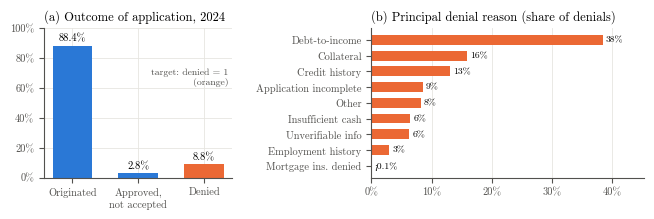

In [10]:
reasons = {"1": "Debt-to-income", "2": "Employment history", "3": "Credit history",
           "4": "Collateral", "5": "Insufficient cash", "6": "Unverifiable info",
           "7": "Application incomplete", "8": "Mortgage ins. denied", "9": "Other"}
rs = df.loc[df.denied == 1, "denial_reason-1"].astype(str).map(reasons).value_counts(normalize=True)
res["denial_reasons"] = rs.to_dict()

fig, ax = plt.subplots(1, 2, figsize=(6.6, 2.25), gridspec_kw={"width_ratios": [1, 1.45]})
shares = pd.Series(res["action_shares"]).rename(
    {1: "Originated", 2: "Approved,\nnot accepted", 3: "Denied"})
bars = ax[0].bar(shares.index, shares.values, color=[BLUE, BLUE, ORANGE], width=0.6)
for b, v in zip(bars, shares.values):
    ax[0].text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.1%}",
               ha="center", va="bottom", fontsize=7.5)
ax[0].yaxis.set_major_formatter(pct)
ax[0].set_ylim(0, 1)
ax[0].set_title("(a) Outcome of application, 2024", loc="left")
ax[0].text(0.98, 0.62, "target: denied = 1\n(orange)", transform=ax[0].transAxes,
           ha="right", fontsize=7, color=MID)

rs = rs.sort_values()
ax[1].barh(rs.index, rs.values, color=ORANGE, height=0.62)
for i, v in enumerate(rs.values):
    ax[1].text(v + 0.005, i, f"{v:.0%}" if v >= 0.005 else "<0.1%", va="center", fontsize=7)
ax[1].xaxis.set_major_formatter(pct)
ax[1].set_xlim(0, rs.max() * 1.18)
ax[1].set_title("(b) Principal denial reason (share of denials)", loc="left")
ax[1].grid(axis="y", visible=False)
fig.tight_layout(w_pad=2)
fig.savefig("figs/fig1_target.pdf")
plt.show()

### Figure 2 - denial rate vs DTI, LTV, income, lender

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


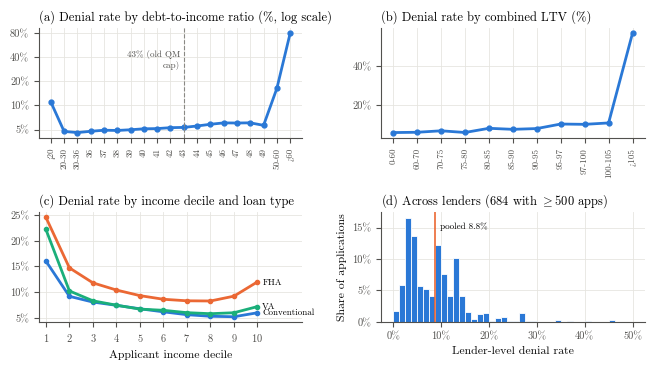

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(6.6, 3.75))

a = ax[0, 0]
g = df[df.dti_cat != "Missing/NA"].groupby("dti_cat", observed=True)["denied"].mean().reindex(dti_order)
a.plot(range(len(g)), g.values, color=BLUE, lw=2, marker="o", ms=3.5)
a.set_xticks(range(len(g)))
a.set_xticklabels(["<20", "20-30", "30-36"] + [str(i) for i in range(36, 50)] + ["50-60", ">60"],
                  rotation=90, fontsize=6.5)
a.set_yscale("log")
a.yaxis.set_major_formatter(pct)
a.set_yticks([0.05, 0.1, 0.2, 0.4, 0.8])
a.yaxis.set_minor_locator(mtick.NullLocator())
a.axvline(dti_order.index("43"), color=GREY, lw=0.8, ls="--")
a.text(dti_order.index("43") - 0.3, 0.3, "43% (old QM\ncap)", ha="right", fontsize=6.5, color=MID)
a.set_title("(a) Denial rate by debt-to-income ratio (%, log scale)", loc="left")

a = ax[0, 1]
ltv_bins = pd.cut(df["loan_to_value_ratio"].clip(upper=110),
                  [0, 60, 70, 75, 80, 85, 90, 95, 97, 100, 105, 110])
g = df.groupby(ltv_bins, observed=True)["denied"].mean()
a.plot(range(len(g)), g.values, color=BLUE, lw=2, marker="o", ms=3.5)
xl = [f"{int(i.left)}-{int(i.right)}" for i in g.index]
xl[-1] = ">105"
a.set_xticks(range(len(g)))
a.set_xticklabels(xl, rotation=90, fontsize=6.5)
a.yaxis.set_major_formatter(pct)
a.set_title("(b) Denial rate by combined LTV (%)", loc="left")

a = ax[1, 0]
decile = pd.qcut(inc, 10, labels=False, duplicates="drop") + 1
for code, color, name in [("1", BLUE, "Conventional"), ("2", ORANGE, "FHA"), ("3", GREEN, "VA")]:
    m = df["loan_type"].astype(str) == code
    g = df[m].groupby(decile[m])["denied"].mean()
    a.plot(g.index, g.values, color=color, lw=2, marker="o", ms=3)
    a.text(g.index[-1] + 0.2, g.values[-1], name, fontsize=6.5, va="center")
a.set_xticks(range(1, 11))
a.set_xlim(0.7, 11.9)
a.yaxis.set_major_formatter(pct)
a.set_xlabel("Applicant income decile")
a.set_title("(c) Denial rate by income decile and loan type", loc="left")

a = ax[1, 1]
lenders = df.groupby("lei", observed=True)["denied"].agg(["mean", "size"])
lenders = lenders[lenders["size"] >= 500]   # drop tiny lenders, their rates are noise
res["lenders_500"] = len(lenders)
res["lender_share_500"] = float(lenders["size"].sum() / N)
res["lender_denial_p10_p90"] = [float(lenders["mean"].quantile(.1)), float(lenders["mean"].quantile(.9))]
a.hist(lenders["mean"], bins=np.linspace(0, 0.5, 41),
       weights=lenders["size"] / lenders["size"].sum(),
       color=BLUE, edgecolor="white", linewidth=0.6)
a.axvline(res["denial_2024"], color=ORANGE, lw=1.2)
a.text(res["denial_2024"] + 0.01, a.get_ylim()[1] * 0.85, f"pooled {res['denial_2024']:.1%}", fontsize=6.5)
a.xaxis.set_major_formatter(pct)
a.yaxis.set_major_formatter(pct)
a.set_xlabel("Lender-level denial rate")
a.set_ylabel("Share of applications")
a.set_title(f"(d) Across lenders ({len(lenders):,} with $\\geq$500 apps)", loc="left")

fig.tight_layout(h_pad=1.2, w_pad=1.5)
fig.savefig("figs/fig2_predictors.pdf")
plt.show()

### Figure 3 - distributions by outcome, raw gap by race

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


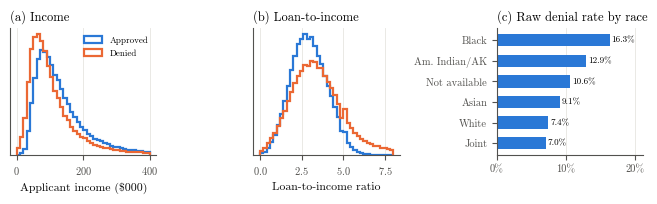

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(6.6, 2.1))
for a, (col, xlabel, rng) in zip(ax[:2], [("income", "Applicant income ($000)", (0, 400)),
                                          ("loan_to_income", "Loan-to-income ratio", (0, 8))]):
    for k, color, name in [(0, BLUE, "Approved"), (1, ORANGE, "Denied")]:
        x = df.loc[df.denied == k, col].dropna()
        x = x[(x > rng[0]) & (x < rng[1])]
        a.hist(x, bins=40, range=rng, density=True, histtype="step", color=color, lw=1.6, label=name)
    a.set_xlabel(xlabel)
    a.set_yticks([])
    a.grid(axis="y", visible=False)
ax[0].legend(loc="upper right", fontsize=6.5)
ax[0].set_title("(a) Income", loc="left")
ax[1].set_title("(b) Loan-to-income", loc="left")

race_names = {"White": "White", "Black or African American": "Black", "Asian": "Asian",
              "Joint": "Joint", "Race Not Available": "Not available",
              "American Indian or Alaska Native": "Am. Indian/AK"}
rr = df.groupby(df["derived_race"].astype(str))["denied"].mean()
rr = rr[list(race_names)].rename(race_names).sort_values()
res["race_denial"] = rr.to_dict()
ax[2].barh(rr.index, rr.values, color=BLUE, height=0.6)
for i, v in enumerate(rr.values):
    ax[2].text(v + 0.003, i, f"{v:.1%}", va="center", fontsize=6.5)
ax[2].xaxis.set_major_formatter(pct)
ax[2].set_xlim(0, rr.max() * 1.3)
ax[2].grid(axis="y", visible=False)
ax[2].set_title("(c) Raw denial rate by race", loc="left")

fig.tight_layout(w_pad=1.2)
fig.savefig("figs/fig3_distributions.pdf")
plt.show()

### Simple rule-based benchmark (what a non-ML underwriter could do)

In [13]:
dti_high = df["dti_cat"].isin(["50%-60%", ">60%"]) | (dti_num >= 50)
ltv = df["loan_to_value_ratio"]
rules = {
    "DTI>=50": dti_high,
    "DTI>=50 or LTV>100": dti_high | (ltv > 100),
    "DTI>43 or LTV>97": dti_high | (dti_num > 43) | (ltv > 97),
}
res["rules"] = {}
for name, flag in rules.items():
    tp = (flag & (df.denied == 1)).sum()
    res["rules"][name] = {"flag_share": float(flag.mean()),
                          "recall": float(tp / df.denied.sum()),
                          "precision": float(tp / flag.sum())}

### Save numbers used in the text

In [14]:
res["median_loan"] = float(df.loan_amount.median())
res["median_income"] = float(df.income.median())
for k, cat in [("lt20", "<20%"), ("30_36", "30%-<36%"), ("50_60", "50%-60%"), ("gt60", ">60%")]:
    res[f"dti_{k}_denial"] = float(df.loc[df.dti_cat == cat, "denied"].mean())

with open("results/eda_numbers.json", "w") as f:
    json.dump(res, f, indent=1, default=float)
print(json.dumps({k: v for k, v in res.items() if k not in ("table1", "table2")}, indent=1, default=float))

{
 "n_2024": 3140857,
 "n_2025": 3139327,
 "denial_2024": 0.08806640990022786,
 "denial_2025": 0.08665328587942575,
 "n_lenders": 2663,
 "n_msa": 418,
 "n_states": 54,
 "action_shares": {
  "1": 0.8836024690076626,
  "2": 0.028331121092109574,
  "3": 0.08806640990022786
 },
 "action_counts": {
  "1": 2775269,
  "2": 88984,
  "3": 276604
 },
 "dti_missing_share": 0.008003548076209774,
 "dti_missing_denial": 0.34294693293022516,
 "leak": {
  "preapproval": {
   "1": {
    "size": 171264,
    "mean": 0.0
   },
   "2": {
    "size": 2969593,
    "mean": 0.09314542430562034
   }
  },
  "initially_payable_to_institution": {
   "1": {
    "size": 2892385,
    "mean": 0.07465223336450715
   },
   "1111": {
    "size": 23,
    "mean": 0.30434782608695654
   },
   "2": {
    "size": 192829,
    "mean": 0.07245279496341318
   },
   "3": {
    "size": 55620,
    "mean": 0.8396799712333692
   }
  }
 },
 "denial_reasons": {
  "Debt-to-income": 0.38401272618810894,
  "Collateral": 0.15830365697138415